In [1]:
import re
from pathlib import Path
from difflib import SequenceMatcher

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
)

project_root = Path.cwd()
if not (project_root / 'data').exists():
    project_root = project_root.parent

train_path = project_root / 'data/5_golden_standard_pair/golden_standard_pair_complete/gs_pair_train_val.csv'
test_path  = project_root / 'data/5_golden_standard_pair/golden_standard_pair_complete/gs_pair_test.csv'

RANDOM_STATE = 42

In [2]:
train = pd.read_csv(train_path)
test  = pd.read_csv(test_path)

required = ['id1', 'id2', 'source_pair', 'hard', 'match',
            'brandName1', 'brandName2',
            'activeSubstances1', 'activeSubstances2',
            'licenceHolder1', 'licenceHolder2']
for df, name in [(train, 'train'), (test, 'test')]:
    assert set(required).issubset(df.columns), f'{name} missing columns'
    assert df['match'].isin([0, 1]).all()

print(f'Train: {len(train)} pairs  |  Test: {len(test)} pairs')
print('\nTrain class distribution:')
display(train.groupby(['source_pair', 'match']).size().unstack(fill_value=0))
print('\nTest class distribution:')
display(test.groupby(['source_pair', 'match']).size().unstack(fill_value=0))

Train: 2973 pairs  |  Test: 525 pairs

Train class distribution:


match,0,1
source_pair,,
dpd_ema,498,352
dpd_fda,442,211
ema_fda,982,488



Test class distribution:


match,0,1
source_pair,,
dpd_ema,87,63
dpd_fda,79,37
ema_fda,173,86


In [3]:
COMPANY_SUFFIXES = {
    'LTD', 'LIMITED', 'INC', 'INCORPORATED', 'CORP', 'CORPORATION',
    'CO', 'COMPANY', 'LLC', 'LLP', 'PLC', 'GMBH', 'AG',
    'BV', 'NV', 'SA', 'SAS', 'SRL', 'SPA',
}

COMMON_SALTS = {
    'HYDROCHLORIDE', 'HCL', 'DIHYDROCHLORIDE', 'MONOHYDROCHLORIDE',
    'SODIUM', 'POTASSIUM', 'CALCIUM', 'MAGNESIUM', 'ZINC',
    'SULFATE', 'SULPHATE', 'PHOSPHATE', 'ACETATE', 'CITRATE',
    'TARTRATE', 'MALEATE', 'FUMARATE', 'SUCCINATE', 'LACTATE',
    'NITRATE', 'BROMIDE', 'IODIDE', 'CHLORIDE', 'GLUCONATE',
    'MONOHYDRATE', 'DIHYDRATE', 'TRIHYDRATE', 'ANHYDROUS', 'HYDRATE',
    'BESYLATE', 'MESYLATE', 'TOSYLATE', 'EMBONATE', 'PAMOATE',
    'VALERATE', 'PROPIONATE', 'BUTYRATE', 'DECANOATE', 'ENANTHATE',
}


def normalise(text: str) -> str:
    if not isinstance(text, str):
        return ''
    return re.sub(r'[^\w\s]', ' ', text.upper()).strip()


def remove_salts(tokens: set) -> set:
    return tokens - COMMON_SALTS


def remove_company_suffixes(tokens: set) -> set:
    return tokens - COMPANY_SUFFIXES


def seq_sim(a: str, b: str) -> float:
    if not a and not b:
        return 1.0
    if not a or not b:
        return 0.0
    return SequenceMatcher(None, a, b).ratio()


def jaccard(set_a: set, set_b: set) -> float:
    if not set_a and not set_b:
        return 1.0
    union = set_a | set_b
    if not union:
        return 0.0
    return len(set_a & set_b) / len(union)


def overlap_coeff(set_a: set, set_b: set) -> float:
    if not set_a and not set_b:
        return 1.0
    smaller = min(len(set_a), len(set_b))
    if smaller == 0:
        return 0.0
    return len(set_a & set_b) / smaller


def extract_features(df: pd.DataFrame) -> np.ndarray:
    rows = []
    for _, row in df.iterrows():
        b1 = normalise(row['brandName1'])
        b2 = normalise(row['brandName2'])
        s1 = normalise(row['activeSubstances1'])
        s2 = normalise(row['activeSubstances2'])
        h1 = normalise(row['licenceHolder1'])
        h2 = normalise(row['licenceHolder2'])

        brand_sim = seq_sim(b1, b2)
        substance_sim = seq_sim(s1, s2)

        tok1 = remove_salts(set(s1.split()))
        tok2 = remove_salts(set(s2.split()))
        substance_jaccard = jaccard(tok1, tok2)

        htok1 = remove_company_suffixes(set(h1.split()))
        htok2 = remove_company_suffixes(set(h2.split()))
        holder_missing = 1 if (not h1 or not h2) else 0
        holder_sim = overlap_coeff(htok1, htok2) if not holder_missing else 0.0

        cnt1 = row.get('activeSubstanceCount1', len(tok1))
        cnt2 = row.get('activeSubstanceCount2', len(tok2))
        count_diff = abs(float(cnt1) - float(cnt2)) if pd.notna(cnt1) and pd.notna(cnt2) else 0.0

        rows.append([brand_sim, substance_sim, substance_jaccard,
                     holder_sim, holder_missing, count_diff])
    return np.array(rows, dtype=float)


FEATURE_NAMES = [
    'brand_sim', 'substance_sim', 'substance_token_jaccard',
    'holder_sim', 'holder_missing', 'substance_count_diff',
]

print('Extracting features...')
X_train = extract_features(train)
y_train = train['match'].values
X_test  = extract_features(test)
y_test  = test['match'].values
print(f'X_train: {X_train.shape}  X_test: {X_test.shape}')
pd.DataFrame(X_train, columns=FEATURE_NAMES).describe().round(3)

Extracting features...


X_train: (2973, 6)  X_test: (525, 6)


,brand_sim,substance_sim,substance_token_jaccard,holder_sim,holder_missing,substance_count_diff
count,2973.000,2973.000,2973.000,2973.000,2973.000,2973.000
mean,0.648,0.653,0.573,0.229,0.054,0.443
std,0.344,0.342,0.459,0.379,0.226,1.545
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.267,0.286,0.000,0.000,0.000,0.000
50%,0.769,0.760,0.750,0.000,0.000,0.000
75%,1.000,1.000,1.000,0.500,0.000,0.000
max,1.000,1.000,1.000,1.000,1.000,25.000


In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# --- SVM ---
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE)),
])
svm_param_grid = {
    'clf__C':     [0.1, 1, 10, 100],
    'clf__gamma': ['scale', 'auto', 0.1, 0.01],
}
svm_search = GridSearchCV(
    svm_pipeline, svm_param_grid,
    scoring='f1_macro', cv=cv, n_jobs=-1, verbose=0,
)
svm_search.fit(X_train, y_train)
print(f'SVM best params:    {svm_search.best_params_}')
print(f'SVM best CV macro F1: {svm_search.best_score_:.4f}')

C:\Users\I775013\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM best params:    {'clf__C': 100, 'clf__gamma': 0.1}
SVM best CV macro F1: 0.8869


In [5]:
# --- Logistic Regression ---
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
lr_param_grid = {
    'clf__C':       [0.01, 0.1, 1, 10, 100],
    'clf__penalty': ['l2'],
    'clf__solver':  ['lbfgs', 'liblinear'],
}
lr_search = GridSearchCV(
    lr_pipeline, lr_param_grid,
    scoring='f1_macro', cv=cv, n_jobs=-1, verbose=0,
)
lr_search.fit(X_train, y_train)
print(f'LR best params:    {lr_search.best_params_}')
print(f'LR best CV macro F1: {lr_search.best_score_:.4f}')

LR best params:    {'clf__C': 0.1, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}
LR best CV macro F1: 0.8760


C:\Users\I775013\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [6]:
def evaluate(name, model, X, y, df):
    pred = model.predict(X)
    report = classification_report(y, pred, target_names=['non-match', 'match'], output_dict=True)
    macro_f1   = f1_score(y, pred, average='macro')
    match_f1   = f1_score(y, pred, pos_label=1)
    match_prec = precision_score(y, pred, pos_label=1)
    match_rec  = recall_score(y, pred, pos_label=1)
    nm_f1      = f1_score(y, pred, pos_label=0)
    cm         = confusion_matrix(y, pred, labels=[0, 1])
    print(f'\n=== {name} — Test Set ===')
    print(f'Macro F1:       {macro_f1:.4f}')
    print(f'Match     — P: {match_prec:.4f}  R: {match_rec:.4f}  F1: {match_f1:.4f}')
    print(f'Non-match — F1: {nm_f1:.4f}')
    print('\nFull classification report:')
    print(classification_report(y, pred, target_names=['non-match', 'match']))
    return pred, cm, report

svm_pred, svm_cm, svm_report = evaluate('SVM', svm_search.best_estimator_, X_test, y_test, test)
lr_pred,  lr_cm,  lr_report  = evaluate('Logistic Regression', lr_search.best_estimator_, X_test, y_test, test)


=== SVM — Test Set ===
Macro F1:       0.8698
Match     — P: 0.9379  R: 0.7312  F1: 0.8218
Non-match — F1: 0.9179

Full classification report:
              precision    recall  f1-score   support

   non-match       0.87      0.97      0.92       339
       match       0.94      0.73      0.82       186

    accuracy                           0.89       525
   macro avg       0.90      0.85      0.87       525
weighted avg       0.89      0.89      0.88       525


=== Logistic Regression — Test Set ===
Macro F1:       0.8610
Match     — P: 0.9241  R: 0.7204  F1: 0.8097
Non-match — F1: 0.9124

Full classification report:
              precision    recall  f1-score   support

   non-match       0.86      0.97      0.91       339
       match       0.92      0.72      0.81       186

    accuracy                           0.88       525
   macro avg       0.89      0.84      0.86       525
weighted avg       0.88      0.88      0.88       525



In [7]:
def breakdown_scores(pred, df, label):
    rows = []
    for col in ['hard', 'source_pair']:
        for val, grp in df.groupby(col):
            idx = grp.index
            mf1 = f1_score(df.loc[idx, 'match'], pred[idx], average='macro')
            pf1 = f1_score(df.loc[idx, 'match'], pred[idx], pos_label=1, zero_division=0)
            nf1 = f1_score(df.loc[idx, 'match'], pred[idx], pos_label=0, zero_division=0)
            rows.append({'group': col, 'value': val, 'n': len(grp),
                         'macro_f1': mf1, 'match_f1': pf1, 'nonmatch_f1': nf1})
    result = pd.DataFrame(rows)
    result['value'] = result['value'].replace({0: 'Ordinary', 1: 'Difficult'})
    result.insert(0, 'model', label)
    return result

svm_breakdown = breakdown_scores(svm_pred, test, 'SVM')
lr_breakdown  = breakdown_scores(lr_pred,  test, 'Logistic Regression')
breakdown_all = pd.concat([svm_breakdown, lr_breakdown], ignore_index=True)

print('--- By Difficulty ---')
display(breakdown_all[breakdown_all['group'] == 'hard'].drop(columns='group').round(4))
print('--- By Source Pair ---')
display(breakdown_all[breakdown_all['group'] == 'source_pair'].drop(columns='group').round(4))

--- By Difficulty ---


,model,value,n,macro_f1,match_f1,nonmatch_f1
0,SVM,Ordinary,290,0.9004,0.8553,0.9454
1,SVM,Difficult,235,0.8349,0.7907,0.8792
5,Logistic Regression,Ordinary,290,0.9004,0.8553,0.9454
6,Logistic Regression,Difficult,235,0.8166,0.7674,0.8658


--- By Source Pair ---


,model,value,n,macro_f1,match_f1,nonmatch_f1
2,SVM,dpd_ema,150,0.9100,0.8926,0.9274
3,SVM,dpd_fda,116,0.7887,0.6885,0.8889
4,SVM,ema_fda,259,0.8728,0.8188,0.9268
7,Logistic Regression,dpd_ema,150,0.8961,0.8760,0.9162
8,Logistic Regression,dpd_fda,116,0.8366,0.7619,0.9112
9,Logistic Regression,ema_fda,259,0.8433,0.7755,0.9111


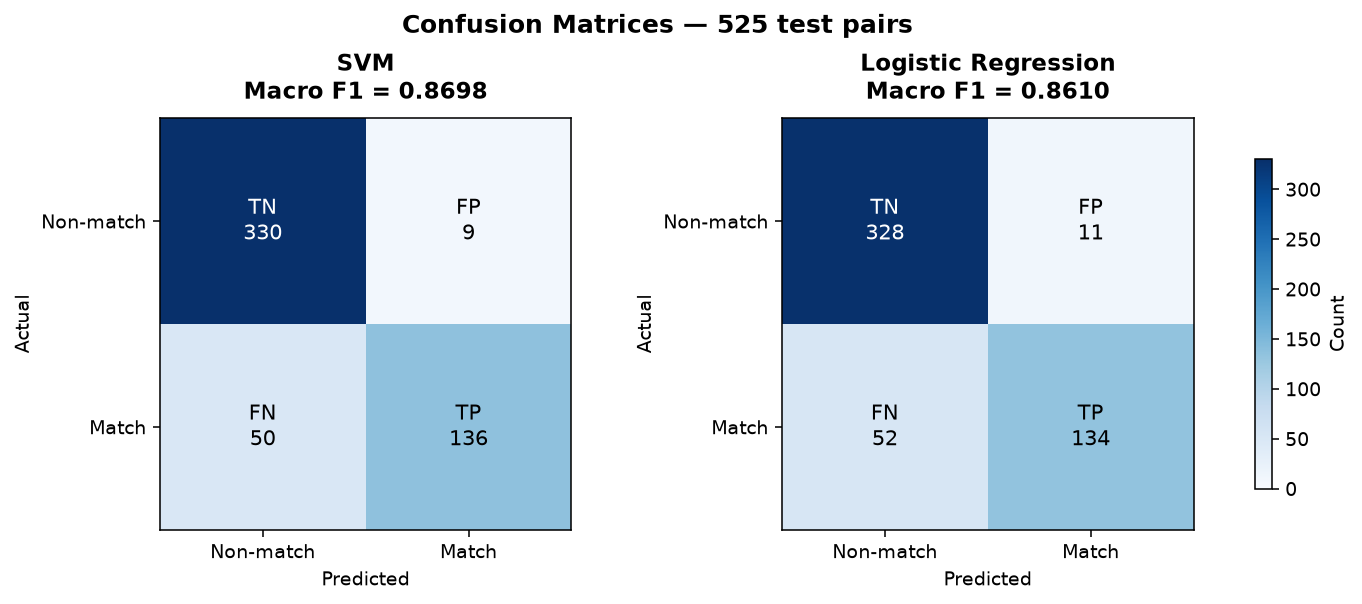

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), dpi=140, layout='constrained')
cell_names = [['TN', 'FP'], ['FN', 'TP']]
models = [('SVM', svm_cm, svm_pred), ('Logistic Regression', lr_cm, lr_pred)]
vmax = max(svm_cm.max(), lr_cm.max())

for ax, (name, cm, pred) in zip(axes, models):
    macro_f1 = f1_score(y_test, pred, average='macro')
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=vmax)
    ax.set_title(f'{name}\nMacro F1 = {macro_f1:.4f}', fontsize=12, fontweight='bold', pad=10)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Non-match', 'Match'])
    ax.set_yticks([0, 1]); ax.set_yticklabels(['Non-match', 'Match'])
    ax.set_xlabel('Predicted', fontsize=10)
    ax.set_ylabel('Actual', fontsize=10)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cell_names[i][j]}\n{cm[i, j]}',
                    ha='center', va='center', fontsize=11,
                    color='white' if cm[i, j] > vmax * 0.6 else 'black')
fig.colorbar(im, ax=axes, shrink=0.8, label='Count')
fig.suptitle(f'Confusion Matrices — {len(test)} test pairs', fontsize=13, fontweight='bold')
plt.savefig(project_root / 'notebooks/ml_classifier_confusion_matrices.png', bbox_inches='tight')
plt.show()

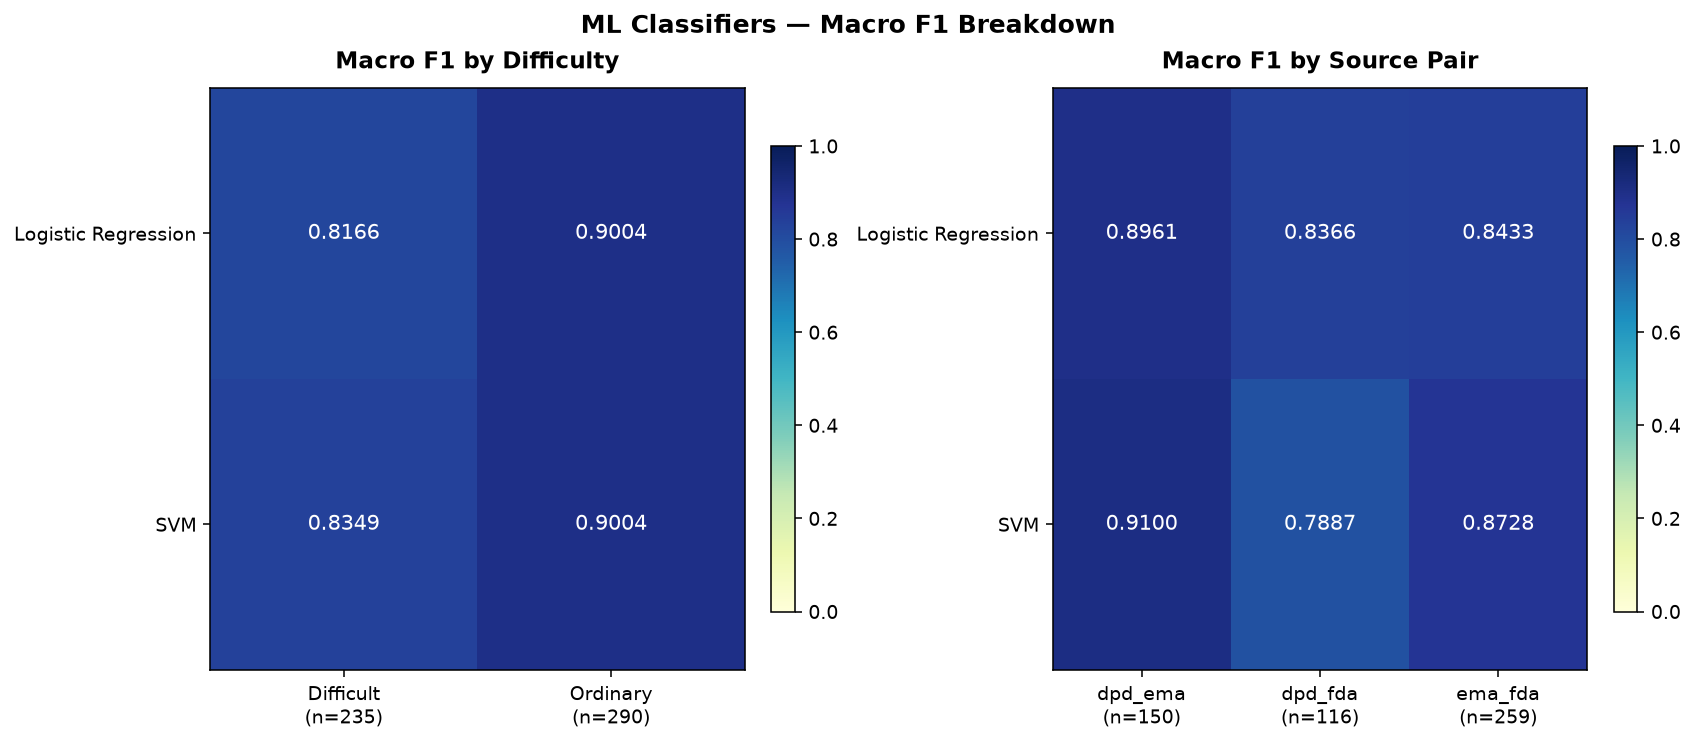

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), dpi=140, layout='constrained')

for ax, col, title in zip(axes, ['hard', 'source_pair'], ['Difficulty', 'Source Pair']):
    sub = breakdown_all[breakdown_all['group'] == col].copy()
    pivot = sub.pivot(index='model', columns='value', values='macro_f1')
    im = ax.imshow(pivot.values, cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
    group_counts = sub.groupby('value')['n'].first()
    xlabels = [f'{v}\n(n={group_counts.get(v, "?")})'  for v in pivot.columns]
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(xlabels, fontsize=10)
    ax.set_yticks(range(len(pivot.index)));   ax.set_yticklabels(pivot.index, fontsize=10)
    ax.set_title(f'Macro F1 by {title}', fontsize=12, fontweight='bold', pad=10)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.values[i, j]
            ax.text(j, i, f'{val:.4f}', ha='center', va='center', fontsize=11,
                    color='white' if val > 0.7 else 'black')
    fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle('ML Classifiers — Macro F1 Breakdown', fontsize=13, fontweight='bold')
plt.savefig(project_root / 'notebooks/ml_classifier_group_macro_f1.png', bbox_inches='tight')
plt.show()

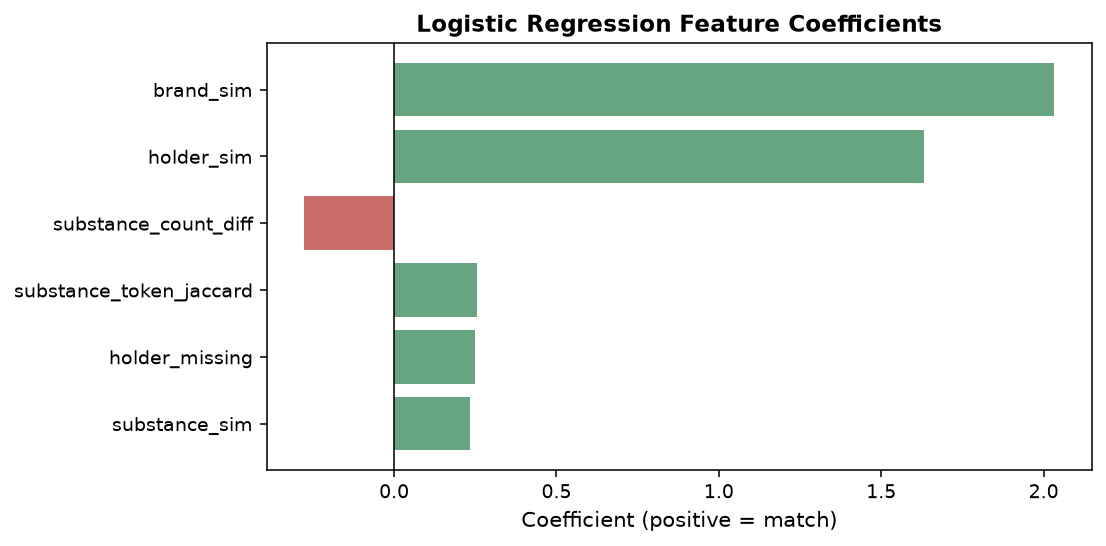

In [10]:
lr_coefs = lr_search.best_estimator_.named_steps['clf'].coef_[0]
coef_df = pd.DataFrame({'feature': FEATURE_NAMES, 'coefficient': lr_coefs})
coef_df = coef_df.reindex(coef_df['coefficient'].abs().sort_values(ascending=True).index)

fig, ax = plt.subplots(figsize=(8, 4), dpi=140)
colors = ['#c96d68' if c < 0 else '#66a580' for c in coef_df['coefficient']]
ax.barh(coef_df['feature'], coef_df['coefficient'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Coefficient (positive = match)', fontsize=11)
ax.set_title('Logistic Regression Feature Coefficients', fontsize=12, fontweight='bold')
ax.tick_params(labelsize=10)
plt.tight_layout()
plt.savefig(project_root / 'notebooks/ml_classifier_lr_coefficients.png', bbox_inches='tight')
plt.show()

In [11]:
summary_rows = []
for name, pred in [('SVM', svm_pred), ('Logistic Regression', lr_pred)]:
    summary_rows.append({
        'Matcher': name,
        'Macro F1': f1_score(y_test, pred, average='macro'),
        'Match P':  precision_score(y_test, pred, pos_label=1),
        'Match R':  recall_score(y_test, pred, pos_label=1),
        'Match F1': f1_score(y_test, pred, pos_label=1),
        'Non-match F1': f1_score(y_test, pred, pos_label=0),
    })
summary = pd.DataFrame(summary_rows).set_index('Matcher')
display(summary.round(4))

,Macro F1,Match P,Match R,Match F1,Non-match F1
Matcher,,,,,
SVM,0.8698,0.9379,0.7312,0.8218,0.9179
Logistic Regression,0.8610,0.9241,0.7204,0.8097,0.9124
